In [ ]:
import torch
from torch.nn import *

xOld = torch.rand(2048, 4)
yOld = xOld.sum(1).to(torch.long)
mOld = Sequential(Linear(4, 16), ReLU(1), Linear(16, yOld.max() + 1))
c = CrossEntropyLoss()

In [ ]:
o = torch.optim.Adam(mOld.parameters(), 0.1, weight_decay=0.001)
for _ in range(10):
    for _ in range(200):
        _ = c(mOld(xOld), yOld)
        _.backward()
        o.step()
        o.zero_grad()
    print(_)
(mOld(xOld).argmax(1) == yOld).sum() / len(xOld)

In [ ]:
xNew = torch.rand(2048, 4) * 10
yNew = xNew.sum(1).to(torch.long)
mNew = Sequential(*mOld[:2], Linear(16, yNew.max() + 1))
with torch.no_grad():
    yNewInOld = mOld(xNew).softmax(1)

In [ ]:
o = torch.optim.Adam(mNew[2].parameters(), 0.1)
for _ in range(10):
    for _ in range(200):
        _ = c(mNew(xNew), yNew)
        _.backward()
        o.step()
        o.zero_grad()
    print(_)

In [ ]:
o = torch.optim.Adam({*mOld.parameters(), *mNew.parameters()}, 0.1)
for _ in range(10):
    for _ in range(1000):
        _ = c(mOld(xNew), yNewInOld) * 0.1 + c(mNew(xNew), yNew)
        _.backward()
        o.step()
        o.zero_grad()
    print(_)

In [ ]:
(mNew(xOld).argmax(1) == yOld).sum() / len(xOld)

In [ ]:
(mNew(xNew).argmax(1) == yNew).sum() / len(xNew)

In [ ]:
o = torch.optim.Adam(mOld.parameters(), *mNew.parameters()}, 0.1)
for _ in range(10):
    for _ in range(100):
        _ = c(mOld(xNew), yNewInOld) * 0.5 + c(mNew(xNew), yNew)
        _.backward()
        o.step()
        o.zero_grad()
    print(_)

In [ ]:
mNew

In [ ]:
(mNew(xOld).argmax(1) == yOld).sum()

In [ ]:
import torch
from torch.nn import *
from tqdm.notebook import tqdm
import numpy as np

lr = 1e-1
lr = np.geomspace(lr * 1e-2, lr * 1e2, 20)
R = []
x = torch.randn(1024, 16)
k = 256
for i in tqdm(lr):
    y = torch.randint(0, 256, [len(x)])
#     m = Linear(16, 256)
    m = Sequential(Linear(16, 24), ReLU(1), Linear(24, 256))
    c = CrossEntropyLoss()
    o = torch.optim.SGD(m.parameters(), i)
    r = []
    for i, v, w in zip(range(k, 99999, k), x.view(-1, k, x.size(1)), y.view(-1, k)):
        for _ in range(2):
            c(m(v), w).backward()
            o.step()
            o.zero_grad()
        with torch.no_grad():
            r.append(int((m(x[:i]).argmax(1) == y[:i]).sum()) / i)
    R.append(r)
R = np.array(R)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(30, 10))
plt.plot(R.T);

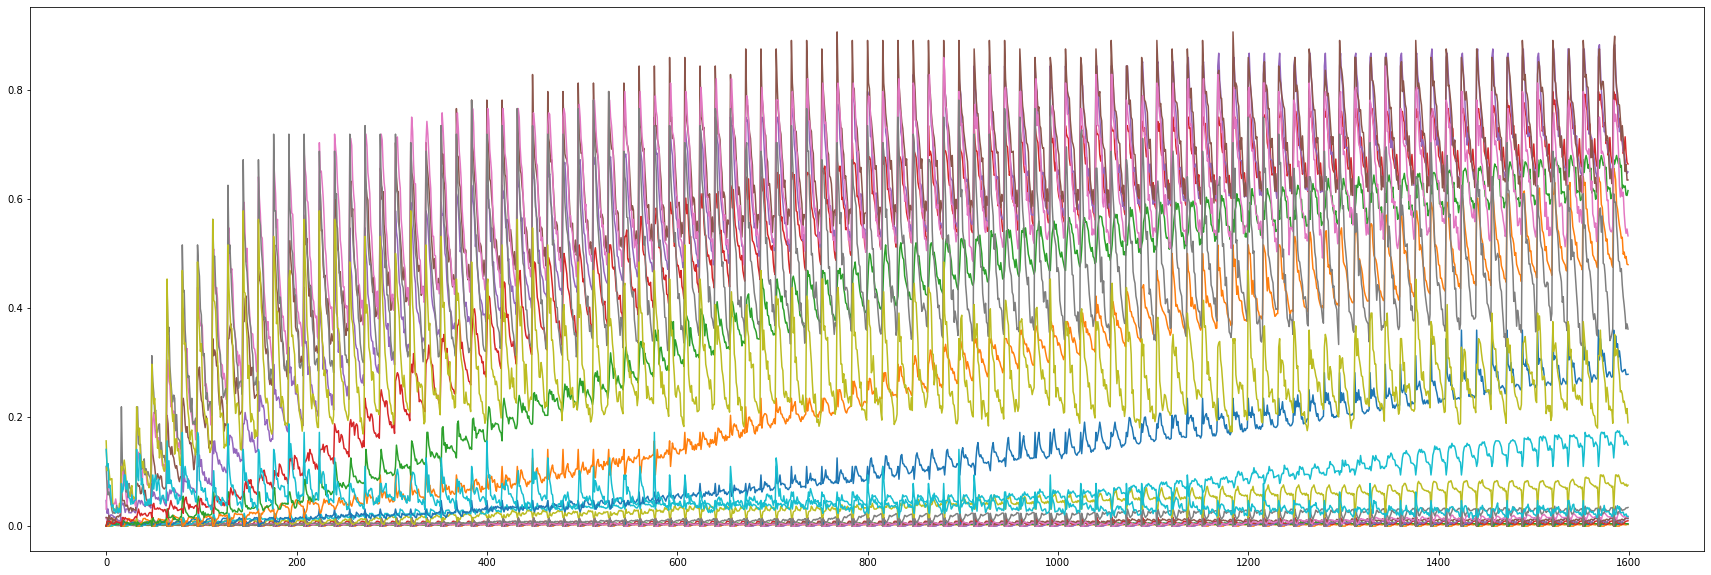